# Zero diagnostics, model decision and freezing

On the **validation** partition, the observed number of zeros is checked for compatibility with the count models already evaluated. This diagnostic is read alongside calibration by exposure and the rule that selects the fixed-offset Poisson. The decision is then documented by freezing the Poisson and the global reference rate.

Results are loaded from the stage 3 and stage 4 artifacts after the origin check. The test partition remains reserved for stage 5 and none of its rows is used here. No ZIP or ZINB was fitted.

In [1]:
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina")
import pandas as pd
from IPython.display import display

from freq_sinistros import artifacts, plots

LANG = "en_us"
ROOT = artifacts.project_root()
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 40
s3 = artifacts.load_outputs(ROOT)
s4 = artifacts.load_stage4(ROOT)

## 1. Origin of the results

**Question.** Do the results derive from the approved file, partitions, protocol and frozen artifact?

In [2]:
display(pd.Series(artifacts.verify_origin(ROOT)["checks"], name="ok"))
display(pd.Series(artifacts.verify_stage4(ROOT)["checks"], name="ok"))

arff_sha256_matches_stage1_manifest      True
arff_sha256_matches_comparison           True
assignments_match_stage2_config          True
assignment_file_hash_matches             True
protocol_amendment_matches_comparison    True
stage2_validation_totals_match           True
test_partition_not_returned              True
Name: ok, dtype: bool

partition_config                  True
protocol_config                   True
stage3_amendment                  True
stage3_comparison_config          True
stage3_validation_metrics         True
stage3_coefficients               True
arff                              True
verify_freeze_ok                  True
reproduction_of_stage3_ok         True
training_sample_matches_stage3    True
test_not_used                     True
Name: ok, dtype: bool

### Insights

All checks were satisfied: the ARFF, the assignments, the amended protocol and the stage 3 result files match the hashes recorded at freezing, the deterministic refit reproduced stage 3, and the freeze verification finished without any refit. The test partition was not used.

## 2. Model decision by the approved rule

**Question.** Does the approved rule select the fixed-offset Poisson on the main partition, and why is the log-likelihood gain of NB2 not enough?

,step,population,dev_global,dev_poisson,dev_nb2,d_dev_poisson_minus_global,d_dev_poisson_minus_global_lo,d_dev_poisson_minus_global_hi,abs_rate_err_global,abs_rate_err_poisson,abs_rate_err_nb2,d_ll_nb2_minus_poisson,d_ll_nb2_minus_poisson_lo,d_ll_nb2_minus_poisson_hi,d_dev_nb2_minus_poisson,d_dev_nb2_minus_poisson_lo,d_dev_nb2_minus_poisson_hi,d_dev_nb2_minus_global,poisson_over_global,nb2_over_poisson,preferred_by_rules
0,100000,validation,0.3286,0.3198,0.3199,-0.0089,-0.0104,-0.0073,0.1313,0.1419,0.0631,0.0008,0.0004,0.0013,0.0001,0.0000,0.0002,-0.0088,False,False,global
1,200000,validation,0.3286,0.3192,0.3193,-0.0094,-0.0109,-0.0079,0.0096,0.0196,0.1765,0.0008,0.0004,0.0013,0.0001,0.0000,0.0002,-0.0093,False,False,global
2,train_full,validation,0.3286,0.3190,0.3191,-0.0096,-0.0111,-0.0082,0.0676,0.0544,0.2584,0.0008,0.0004,0.0013,0.0001,0.0000,0.0002,-0.0095,True,False,poisson
3,train_full,grouped_validation,0.3374,0.3261,0.3261,-0.0114,-0.0129,-0.0099,0.2570,0.2439,0.0551,0.0014,0.0007,0.0023,-0.0000,-0.0001,0.0001,-0.0114,True,True,nb2


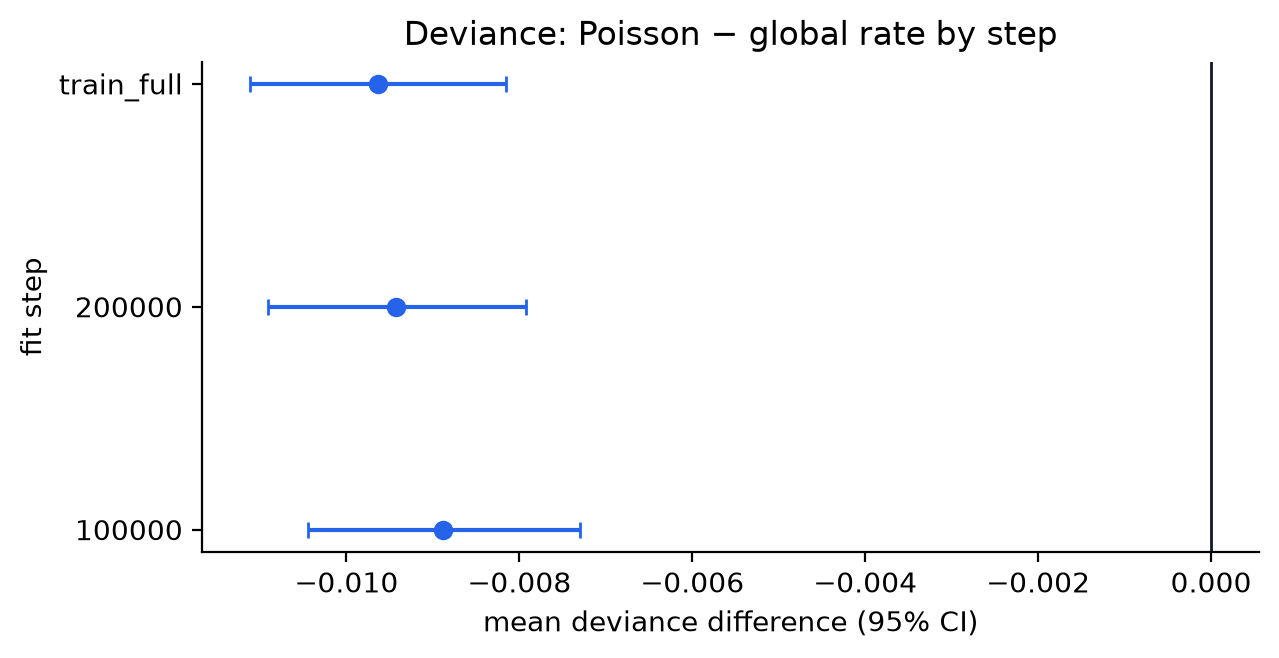

In [3]:
decision = s4["model_decision"]
display(artifacts.localize(decision, LANG))
plots.show(plots.plot_stability(decision, LANG))

### Insights

On the full training set (main partition), the mean deviance is 0.32863 (global rate), 0.31899 (Poisson) and 0.31910 (NB2). The paired Poisson − global rate difference is -0.00964 (95% CI -0.01111 to -0.00815; negative values favor Poisson), and the absolute overall-rate error is 0.054 for Poisson and 0.068 for the global rate, so both conditions of the opinion are met. The sign of the deviance gain is the same in the three steps (-0.00888 with 100,000, -0.00942 with 200,000 and -0.00964 on the full training set). The overall-calibration condition, however, is not met at the smaller steps: the Poisson error is 0.142 against 0.131 (100,000) and 0.020 against 0.010 (200,000). NB2 improves the log-likelihood over Poisson by 0.00075 (CI 0.00036 to 0.00130), but its mean deviance is higher by 0.00011 (CI 0.00003 to 0.00019) and its overall-rate error is 0.258, larger than Poisson's; the NB2 conditions are not met and the likelihood gain alone is insufficient to select it. On the grouped partition, which is a sensitivity with its own population, the NB2 conditions are met (deviance difference -0.00001, CI -0.00009 to 0.00007; overall-rate error 0.055 against 0.244); this result measures generalization to distinct profiles and does not change the decision on the main partition.

## 3. Interpretation of exposure

**Question.** How do the observed rate and the rates predicted by the fixed-offset Poisson and by the diagnostic with a free `log(Exposure)` coefficient compare by exposure band? Rates are `100 × Σμ / Σ Exposure` of the group, computed from direct predictions.

,band,records,exposure,observed_rate_per_100,predicted_rate_poisson,diff_poisson,diff_poisson_lo,diff_poisson_hi,predicted_rate_poisson_free_exposure,diff_poisson_free_exposure,diff_poisson_free_exposure_lo,diff_poisson_free_exposure_hi,low support
0,"(0, 0.02]",2873,32.2187,238.9918,14.2353,-224.7565,-281.5361,-169.5894,134.5604,-104.4314,-160.9391,-50.0374,False
1,"(0.02, 0.08]",14314,916.7600,36.2145,12.4445,-23.7700,-28.3236,-19.4153,43.5083,7.2939,2.7534,11.6179,False
2,"(0.08, 0.25]",16322,"2,815.9400",23.6866,12.0673,-11.6193,-13.4583,-9.8619,23.3901,-0.2965,-2.1118,1.4410,False
3,"(0.25, 0.50]",19693,"7,714.6600",12.3661,11.4387,-0.9274,-1.7519,-0.1328,13.5760,1.2100,0.3847,2.0146,False
4,"(0.50, 0.75]",13882,"8,784.5000",9.9721,11.3045,1.3324,0.6494,1.9866,10.0449,0.0728,-0.6232,0.7261,False
5,"(0.75, 1)",9263,"8,079.5200",8.9981,10.6619,1.6639,0.9571,2.2909,8.0031,-0.9950,-1.6757,-0.3833,False
6,= 1,25042,"25,042.0000",6.9004,8.6950,1.7946,1.4735,2.1069,6.8727,-0.0277,-0.3479,0.2851,False
7,> 1,184,204.4500,3.4238,11.8880,8.4641,NaN,NaN,7.3221,3.8983,NaN,NaN,True
8,total,101573,"53,590.0487",10.0168,10.0711,0.0544,-0.2167,0.3044,10.1012,0.0844,-0.1837,0.3429,False


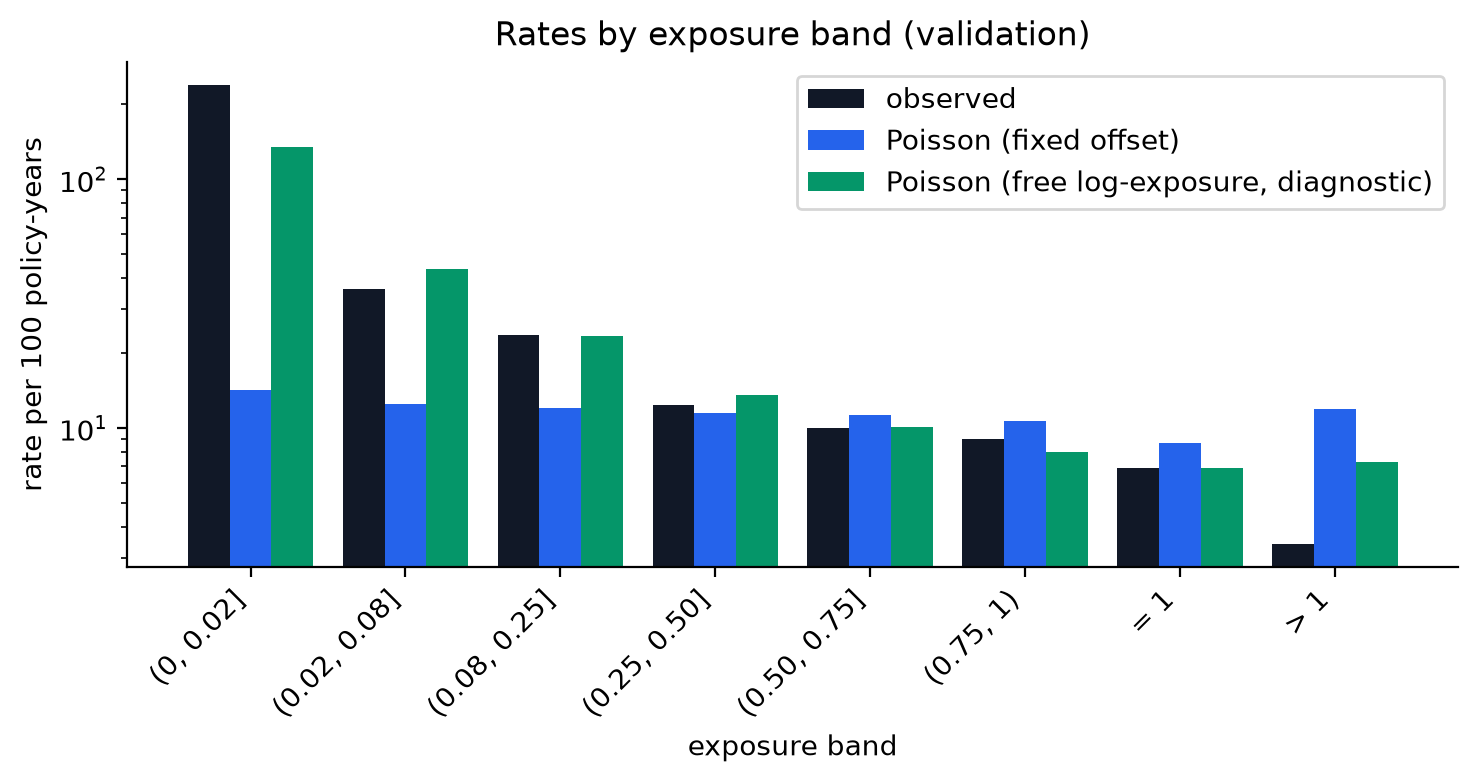

In [4]:
bands = s4["exposure_band_rates"]
cols = ["band", "rows", "exposure", "observed_rate_per_100",
        "predicted_rate_poisson", "diff_poisson", "diff_poisson_lo",
        "diff_poisson_hi", "predicted_rate_poisson_free_exposure",
        "diff_poisson_free_exposure", "diff_poisson_free_exposure_lo",
        "diff_poisson_free_exposure_hi", "low_support"]
display(artifacts.localize(bands[cols], LANG))
plots.show(plots.plot_exposure_rates(bands, LANG))

### Insights

In the `(0; 0.02]` band, the observed rate is 238.99 per 100 policy-years, the offset Poisson predicts 14.24 and the free fit predicts 134.56: the improvement is partial and a substantial gap remains. At exactly one year, the observed value is 6.90, the offset predicts 8.70 and the free fit 6.87. The free fit reduces the gaps in most bands (not in `(0.25; 0.50]`), but the absolute overall-rate error rises from 0.054 to 0.084. The 95% intervals come from the paired bootstrap of stage 3 and exist only where there is support. The free fit is kept as a diagnostic of association with the duration observed in the benchmark; the relation does not support a causal or prospective extrapolation of the frequency to another duration.

## 4. Formal zero diagnostic

**Question.** How many zeros are predicted, `Σ P(Y_i = 0)`, compared with those observed, in total and by band? For the Poisson candidates (including the global rate), `P(Y_i = 0) = exp(−μ_i)`; for NB2, the expression with the estimated dispersion is used.

,candidate,band,records,exposure,zeros_observed,zeros_predicted,diff_pred_minus_obs,CI low,CI high,low support,zero_share_observed,zero_share_predicted
0,global,overall,101573,"53,590.0487",96496,"96,374.8778",-121.1222,-247.7327,4.6260,False,0.9500,0.9488
1,global,"(0, 0.02]",2873,32.2187,2801,"2,869.7533",68.7533,52.7164,86.7374,False,0.9749,0.9989
2,global,"(0.02, 0.08]",14314,916.7600,14000,"14,221.8731",221.8731,188.2801,256.6375,False,0.9781,0.9936
3,global,"(0.08, 0.25]",16322,"2,815.9400",15684,"16,040.6970",356.6970,305.6884,405.7248,False,0.9609,0.9828
4,global,"(0.25, 0.50]",19693,"7,714.6600",18789,"18,930.7832",141.7832,86.4001,198.9132,False,0.9541,0.9613
5,global,"(0.50, 0.75]",13882,"8,784.5000",13061,"13,024.2054",-36.7946,-88.0614,17.7014,False,0.9409,0.9382
6,global,"(0.75, 1)",9263,"8,079.5200",8588,"8,483.2291",-104.7709,-149.6058,-55.9864,False,0.9271,0.9158
7,global,= 1,25042,"25,042.0000",23396,"22,639.8166",-756.1834,-828.1577,-680.9087,False,0.9343,0.9041
8,global,> 1,184,204.4500,177,164.5201,-12.4799,NaN,NaN,True,0.9620,0.8941
9,poisson,overall,101573,"53,590.0487",96496,"96,406.5733",-89.4267,-210.5667,42.9631,False,0.9500,0.9491


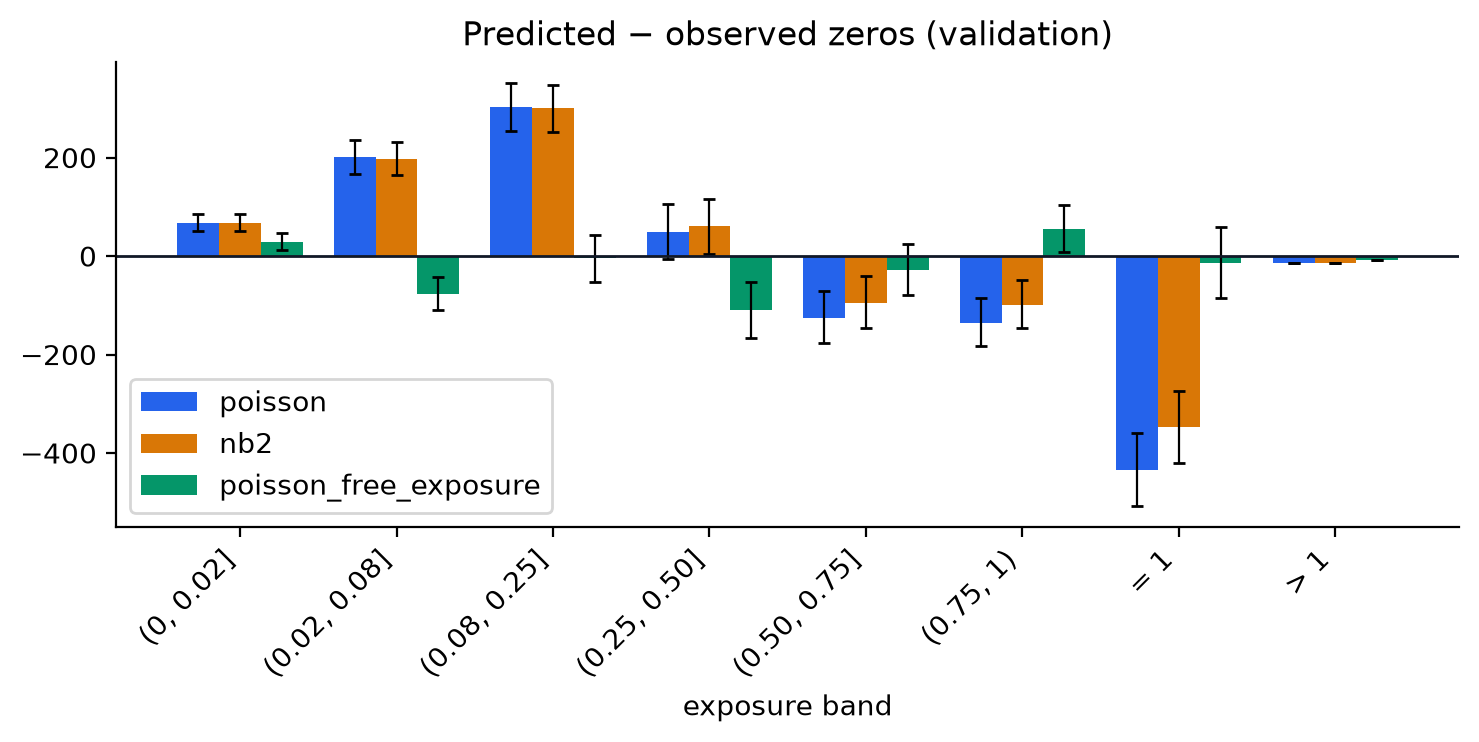

candidate
global                   True
nb2                      True
poisson                  True
poisson_free_exposure    True
Name: ok, dtype: bool

,bands_with_support_ci_below_zero,numeric_requirement_met,total_ci,total_ci_below_zero,total_diff
global,"(0.75, 1), = 1",False,"[-247.732699, 4.625978]",False,-121.1222
nb2,"(0.50, 0.75], (0.75, 1), = 1",False,"[-52.287517, 200.657534]",False,69.5231
poisson,"(0.50, 0.75], (0.75, 1), = 1",False,"[-210.566694, 42.963092]",False,-89.4267
poisson_free_exposure,"(0.02, 0.08], (0.25, 0.50]",True,"[-283.132737, -29.969319]",True,-160.2140


In [5]:
zeros = s4["zero_diagnostics"]
display(artifacts.localize(zeros, LANG))
plots.show(plots.plot_zero_diff(
    zeros, LANG, ("poisson", "nb2", "poisson_free_exposure")))
display(artifacts.zero_reconciliation_ok(s4))
display(artifacts.zero_gate_table(s4))

### Insights

The bands reconcile with the total for all candidates (records, exposure, observed and predicted zeros). Overall, the predicted − observed difference is -121.1 for the global rate (CI -247.7 to 4.6), -89.4 for the offset Poisson (CI -210.6 to 43.0) and 69.5 for NB2 (CI -52.3 to 200.7); all three intervals include zero, so the numerical criterion of stage 2 is not met by the reference model. The offset Poisson overestimates zeros in short bands and underestimates them in long bands (`(0.50, 0.75]`, `(0.75, 1)`, `= 1` have an interval below zero), that is, the sign depends on duration. The free-coefficient diagnostic meets the numerical part: -160.2 overall (CI -283.1 to -30.0), with deficits in `(0.02; 0.08]` (-78.0; CI -110.1 to -42.9) and in `(0.25; 0.50]` (-110.5; CI -166.3 to -51.9), both with support. This difference between models is recorded separately: the criterion applies to the reference model, and the free-fit result is a diagnostic.

A deficit means that fewer zeros were predicted than observed. Across the validation set, the high share of policies with no claims was consistent with the fixed-offset Poisson model. The deficit in the free-coefficient diagnostic shows that this comparison is sensitive to how exposure is modeled.

For the reference model, the overall deficit was not distinguishable from zero. Because the data contract also did not support a second process that always generates zeros, fitting ZIP or ZINB was unnecessary for this evaluation.

## 5. Mean errors and zero differences

**Question.** Do the count errors by duration coexist with the zero differences? The rescaled column adjusts `μ` by band to add up to the observed counts and recomputes the predicted zeros; it is only a diagnostic and is never used for rates or predictions.

In [6]:
display(artifacts.localize(s4["mean_vs_zero_by_band"], LANG))

,candidate,band,records,claims_observed,claims_predicted,claims_diff_pred_minus_obs,zeros_observed,zeros_predicted,zeros_diff_pred_minus_obs,zeros_diff_if_band_rescaled
0,poisson,"(0, 0.02]",2873,77,4.5864,-72.4136,2801,"2,868.4209",67.4209,-2.9978
1,poisson,"(0.02, 0.08]",14314,332,114.0865,-217.9135,14000,"14,200.5921",200.5921,-12.3171
2,poisson,"(0.08, 0.25]",16322,667,339.8079,-327.1921,15684,"15,987.3923",303.3923,-9.2632
3,poisson,"(0.25, 0.50]",19693,954,882.4567,-71.5433,18789,"18,838.1559",49.1559,-17.8127
4,poisson,"(0.50, 0.75]",13882,876,993.0425,117.0425,13061,"12,935.8254",-125.1746,-18.3244
5,poisson,"(0.75, 1)",9263,727,861.4330,134.4330,8588,"8,451.9926",-136.0074,-15.7597
6,poisson,= 1,25042,1728,"2,177.4134",449.4134,23396,"22,962.2838",-433.7162,-20.0520
7,poisson,> 1,184,7,24.3049,17.3049,177,161.9102,-15.0898,0.1960
8,poisson_free_exposure,"(0, 0.02]",2873,77,43.3536,-33.6464,2801,"2,830.0834",29.0834,-3.6310
9,poisson_free_exposure,"(0.02, 0.08]",14314,332,398.8671,66.8671,14000,"13,921.9991",-78.0009,-13.2312


### Insights

In the offset Poisson, the count errors by band have the opposite sign to the zero differences: where counts are underestimated, zeros are overestimated, and vice versa. When `μ` is rescaled by band to match the observed counts, the zero differences by band shrink to a few tens, with a balance of -96.3 for Poisson and -115.1 for the free diagnostic. This residual balance is small and has no associated interval; it does not allow concluding for a second zero-generating process.

## 6. What the data contract supports about a second process

**Question.** Do the dictionary and schema support a plausible hypothesis for a second zero-generating process, a requirement separate from the numerical criterion?

In [7]:
display(artifacts.second_process_table(s4))

criterion                ZIP/ZINB na etapa 4 somente se o modelo de con...
hypothesis_documented                                                False
contract_evidence        O dicionario define ClaimNb como numero de sin...
decision                 encerrar com os modelos de contagem ja avaliad...
dtype: object

### Insights

The dictionary defines `ClaimNb` as the number of claims in the exposure period and `Exposure` as the duration in years (Dutang & Charpentier, 2018); it does not describe risk-free policies, there are neither dates nor a higher-level unit identifier, and the measurement time of `BonusMalus` is unknown. Hence, no hypothesis of a second process is supported by the contract. The Vuong test is not used as a selection rule, because its use to test zero inflation is questioned in the literature (Wilson, 2015). Since the reference model does not meet the numerical criterion and no hypothesis is documented, the decision of this round is to close with the count models already evaluated, without fitting ZIP or ZINB.

## 7. Frozen model and verification

**Question.** What was frozen, and does the verification restore the artifact and reproduce the approved validation without refitting or relearning the preprocessing?

In [8]:
frozen = s4["frozen_model"]
display(pd.Series({
    "model": frozen["model"], "reference": frozen["reference"],
    "columns": len(frozen["estimator"]["columns"]),
    "n_fit": frozen["estimator"]["n_fit"],
    "global_rate": frozen["global_rate"]["rate"],
    "bonus_malus_included": frozen["estimator"]["bonus_malus_included"],
    "training_sample_sha256": frozen["training_sample"]["ids_sha256"]}))
display(pd.Series(frozen["hashes"]))
display(pd.Series({k: v for k, v in s4["verify_freeze"].items()
                   if not isinstance(v, dict)}))
display(pd.Series(s4["verify_freeze"]["frozen_reference"]))

model                                                  poisson_offset_fixed
reference                                                       global_rate
columns                                                                  68
n_fit                                                                474581
global_rate                                                          0.1008
bonus_malus_included                                                  False
training_sample_sha256    2a1dc6791f5f6417818ef6533ad04f14af4daa417c7822...
dtype: object

arff_sha256                         a45363e056e2ea56408b38eeb9d4d04d7f6c6982eb7a14...
assignments_sha256                  f14f53509d63ff468f025fd43096a5c2d12ba3fdd48529...
partition_config_sha256             3bc52dca60401a3eedbccfc3b689216dc02ddfba0d7a79...
protocol_config_sha256              e43e69566690ba98411620e8315bbc27aa00f6702e9cba...
stage3_coefficients_sha256          2c080c077a690c440ede9951aa43a6efb9946bac963448...
stage3_comparison_config_sha256     c0c5001514f67b4cebfe5649cd60392ee2e272db173ec4...
stage3_intervals_sha256             d31e9e8eb360038263d40d88b8d81e631c70c2f19c5d2c...
stage3_preprocessing_sha256         86fddf12dc071564df6a758dbcc2264378a1025794ffbd...
stage3_protocol_amendment_sha256    b4274c81e4d32e5351e7502dadeeb022665dbc3a93cdd3...
stage3_validation_metrics_sha256    cea8459863517021cfefd50546f2660d0fc3473ae08290...
dtype: str

approved_stage3_ok         True
code_modules_unchanged     True
ok                         True
preprocessor_relearned    False
refit_performed           False
test_used                 False
dtype: bool

max_abs_diff   0.0000
max_rel_diff   0.0000
n_compared         77
ok               True
dtype: object

### Insights

The artifact freezes the fixed-offset Poisson, fitted on 474,581 training records with 68 columns and without `BonusMalus`, and the global rate of 10.084 per 100 policy-years computed on the same training set, together with the already fitted preprocessor, the column order, the coefficients and the origin hashes. The verification restored the persisted state, without refitting the estimator or relearning the preprocessing, and reproduced 77 validation aggregates with a maximum absolute difference of 0.000000000000, within the declared tolerance (`rtol = 1e-9`, `atol = 1e-12`); coefficients are persisted with 17 significant digits and restored without loss. The deviation by duration (section 3) is a limitation of the selected Poisson: the fixed offset underestimates very short exposures and overestimates long ones.

## 8. Stage 5 script and limitations

**Question.** How will the final evaluation be applied, and what must be stated as a limitation?

In [9]:
script = s4["stage5_script"]
display(pd.Series({k: v for k, v in script.items()
                   if k in ("model", "reference", "primary_metric",
                            "paired_comparison", "calibration",
                            "test_access", "outputs")}))
display(pd.Series(script["limitations_to_state"], name="limitation"))

calibration          totais previstos e observados e diferenca prev...
model                                             poisson_offset_fixed
outputs                                               outputs/etapa_05
paired_comparison    diferenca de desvio Poisson - taxa global, IC ...
primary_metric       desvio medio de Poisson por registro, previsoe...
reference                                                  global_rate
test_access          uma unica execucao sobre a particao de teste, ...
dtype: str

0    o offset fixo subestima as exposicoes muito cu...
1                     resultados internos ao benchmark
2                            BonusMalus fora do modelo
3                                         sem ZIP/ZINB
Name: limitation, dtype: str

### Insights

Stage 5 will apply the script once to the test partition, after acceptance, with the frozen Poisson and the global reference rate, the mean Poisson deviance, the paired difference against the global rate, the calibration of direct predictions by segment with the shortest band visible, the reconciliations and the hash verification. The limitations to state are the duration bias of the fixed offset, the restriction to the benchmark, the exclusion of `BonusMalus` and the absence of ZIP and ZINB. The results are internal to the benchmark and `production_eligible` remains false.

## References

- Dutang, C., & Charpentier, A. (2018). *CASdatasets: Insurance datasets* (freMTPL2freq). https://dutangc.github.io/CASdatasets/reference/freMTPL.html
- Wilson, P. (2015). The misuse of the Vuong test for non-nested models to test for zero-inflation. *Economics Letters, 127*, 51–53. https://doi.org/10.1016/j.econlet.2014.12.029